<a href="https://colab.research.google.com/github/242031027-afk/Ai-search-algorithm-/blob/main/DFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DFS Path: ['A', 'B', 'E', 'F']


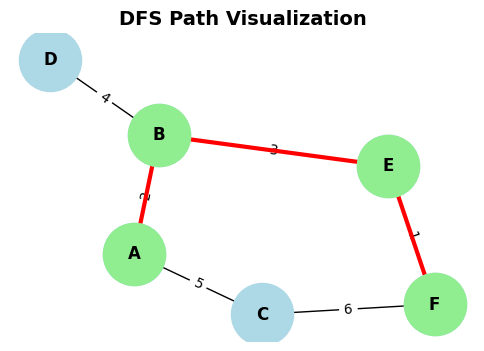

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

# Graph Definition
graph = {
    'A': {'B': 2, 'C': 5}, 'B': {'A': 2, 'D': 4, 'E': 3},
    'C': {'A': 5, 'F': 6}, 'D': {'B': 4},
    'E': {'B': 3, 'F': 1}, 'F': {'C': 6, 'E': 1}
}

def visualize_search(graph, path, title):
    G = nx.Graph()
    for node, edges in graph.items():
        for adj, weight in edges.items():
            G.add_edge(node, adj, weight=weight)
    pos = nx.spring_layout(G)
    plt.figure(figsize=(6, 4))
    plt.title(title, fontsize=14, fontweight='bold')
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_weight='bold')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'))

    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=3)
        nx.draw_networkx_nodes(G, pos, nodelist=path, node_color='lightgreen', node_size=2000)
    plt.show()

# DFS Algorithm
def dfs(graph, start, goal, path=None, visited=None):
    if visited is None: visited = set()
    if path is None: path = [start]
    visited.add(start)
    if start == goal: return path
    for adjacent in graph.get(start, []):
        if adjacent not in visited:
            new_path = dfs(graph, adjacent, goal, path + [adjacent], visited)
            if new_path: return new_path
    return []

# Run & Visualize
path = dfs(graph, 'A', 'F')
print("DFS Path:", path)
visualize_search(graph, path, "DFS Path Visualization")
